# Next week at Keppetipola
Can bagging, boosting or stacking improve on using the latest week's wholesale price? Each forecast is issued after Sunday for the next Monday–Sunday period. Prices are LKR/kg. We predict the mean of reported, observed days in the target week.

**Source:** Anton Jayakody, [Keppetipola Wholesale Vegetable Prices Dataset](https://zenodo.org/records/24214018), compiled from Keppetipola Dedicated Economic Centre bulletins. The [datasheet](https://github.com/tobijay666/Sri-Lankan-Agri-Food-Economic-Open-Data) documents corrections, coverage gaps and the Apache 2.0 licence. ChatGPT generated the code and explanatory text.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit
from IPython.display import display

out = Path("results")
out.mkdir(exist_ok=True)
raw = pd.read_csv("data/prices.csv", parse_dates=["Date"])
print("Raw rows, crops, recorded dates:", len(raw), raw.Vegetable.nunique(), raw.Date.nunique())
print(raw.Date.min(), raw.Date.max())
print(raw.Data_Quality_Flag.value_counts())
assert not raw.duplicated(["Date","Vegetable"]).any()
assert raw.Unit.eq("LKR/kg").all()
obs = raw.loc[raw.Data_Quality_Flag.eq("Observed") & raw.Price_Clean_LKR.gt(0)].copy()
obs["week"] = obs.Date.dt.to_period("W-SUN").dt.start_time
weekly = obs.groupby(["Vegetable","week"]).Price_Clean_LKR.agg(["mean","count"])
print("Positive observed records:", len(obs))

Raw rows, crops, recorded dates: 6815 16 427
2024-01-01 00:00:00 2026-05-29 00:00:00
Data_Quality_Flag
Observed           6112
Carried_Forward     703
Name: count, dtype: int64
Positive observed records: 6112


### Build examples on a real calendar
Require at least three observed prices in each week used. Compare the target week with the three immediately preceding weeks. Calendar joins prevent a months-long gap from becoming a one-week lag. Exclude the partial final calendar week. Pool vegetables to share information across short series. The current week's price is the persistence baseline.

In [2]:
weekly = weekly[weekly["count"] >= 3].reset_index()
examples = weekly.rename(columns={"mean":"actual","count":"observed_days"})
examples = examples[examples.week + pd.Timedelta(days=6) <= raw.Date.max()]
for lag in (1, 2, 3):
    previous = weekly[["Vegetable","week","mean"]].copy()
    previous["week"] += pd.Timedelta(weeks=lag)
    examples = examples.merge(previous.rename(columns={"mean":f"lag{lag}"}),
                              on=["Vegetable","week"], validate="one_to_one")
examples = examples.sort_values(["week","Vegetable"]).reset_index(drop=True)
examples["trend"] = examples.lag1 - examples.lag2
weeks = examples.week.drop_duplicates().sort_values().to_numpy()
cut = weeks[int(0.8*len(weeks))]
train = examples[examples.week < cut].reset_index(drop=True)
test = examples[examples.week >= cut].reset_index(drop=True)
assert train.week.max() < test.week.min()
features = ["Vegetable","lag1","lag2","lag3","trend"]
print("Train and test crop-weeks:", len(train), len(test))
for frame in [train,test]:
    print(frame.week.nunique(),"target weeks from",frame.week.min().date(),"to",frame.week.max().date())

Train and test crop-weeks: 656 176
41 target weeks from 2024-01-22 to 2026-03-02
11 target weeks from 2026-03-09 to 2026-05-18


### Train and stack forecasts
Fit the change from the previous week to focus on movement around the latest known price. Random Forest averages bootstrapped trees. Gradient Boosting adds trees to reduce residual errors. For stacking, fit a non-negative linear combination of their forecasts with weights summing to one. Learn the weight on expanding-window validation predictions. All crops in a target week stay together. Only earlier outcomes can train a model for a later week. Hyperparameters are fixed before test evaluation.

In [3]:
names = ["Random Forest","Gradient Boosting"]
def fit_pair(frame):
    estimators = [RandomForestRegressor(n_estimators=200,min_samples_leaf=5,random_state=4371,n_jobs=2),
                  GradientBoostingRegressor(n_estimators=90,max_depth=2,min_samples_leaf=6,
                                            learning_rate=.04,loss="huber",random_state=4371)]
    pair = {}
    for name, estimator in zip(names, estimators):
        prep = ColumnTransformer([("crop",OneHotEncoder(handle_unknown="ignore",sparse_output=False),["Vegetable"])],
                                 remainder="passthrough")
        pair[name] = make_pipeline(prep,estimator).fit(frame[features],frame.actual-frame.lag1)
    return pair

def forecasts(pair, frame):
    return np.column_stack([np.maximum(0,frame.lag1 + pair[name].predict(frame[features])) for name in names])

validation = []
training_weeks = train.week.drop_duplicates().to_numpy()
for earlier,later in TimeSeriesSplit(n_splits=4).split(training_weeks):
    fit = train[train.week.isin(training_weeks[earlier])]
    val = train[train.week.isin(training_weeks[later])]
    assert fit.week.max() < val.week.min()
    validation.append(np.column_stack([forecasts(fit_pair(fit),val),val.actual]))
rf,gb,actual = np.vstack(validation).T
weight = min(np.linspace(0,1,101), key=lambda w: mean_absolute_error(actual,w*rf+(1-w)*gb))
pair = fit_pair(train)
test[names] = forecasts(pair,test)
test["Stacking"] = weight*test[names[0]]+(1-weight)*test[names[1]]
test["Last week"] = test.lag1
methods = ["Last week",*names,"Stacking"]
scores = test[methods].sub(test.actual,axis=0).abs().mean().sort_values()
print(f"Validation-selected forest weight: {weight:.0%}")
print("Test MAE (LKR/kg):")
print(scores.round(2))
joblib.dump(dict(models=pair,weight=weight,features=features),out/"models.joblib",compress=3)
test.to_csv(out/"forecasts.csv",index=False)

Validation-selected forest weight: 0%
Test MAE (LKR/kg):
Last week            27.89
Gradient Boosting    28.26
Stacking             28.26
Random Forest        30.53
dtype: float64


### Interpret the errors
MAE is the mean absolute difference in rupees per kilogram, giving each crop-week equal weight. Split the test examples by the size of the actual weekly movement. The threshold is the median absolute movement in training. This retrospective grouping helps explain errors after the price is observed.

In [4]:
threshold = (train.actual-train.lag1).abs().median()
test["movement"] = np.where((test.actual-test.lag1).abs()>threshold,"Larger move","Smaller move")
errors = test[methods].sub(test.actual,axis=0).abs()
groups = errors.groupby(test.movement).mean()
groups.insert(0,"Examples",test.movement.value_counts())
print("Training threshold (LKR/kg):",round(threshold,2))
display(groups.round(2))
winner = scores.index[0]
print(f"{winner} leads on this period with MAE {scores.iloc[0]:.2f}.")
print("Largest stacking miss:")
display(test.loc[[errors.Stacking.idxmax()],["Vegetable","week","lag1","actual",*names,"Stacking"]])
groups.to_csv(out/"movement.csv")
print("Base-model signed-error correlation:",round((test[names[0]]-test.actual).corr(test[names[1]]-test.actual),3))

Training threshold (LKR/kg): 23.0


,Examples,Last week,Random Forest,Gradient Boosting,Stacking
movement,,,,,
Larger move,63,61.69,61.34,60.25,60.25
Smaller move,113,9.05,13.35,10.42,10.42


Last week leads on this period with MAE 27.89.
Largest stacking miss:


,Vegetable,week,lag1,actual,Random Forest,Gradient Boosting,Stacking
158,Salada,2026-05-11,106.0,257.142857,118.386858,110.565755,110.565755


Base-model signed-error correlation: 0.97


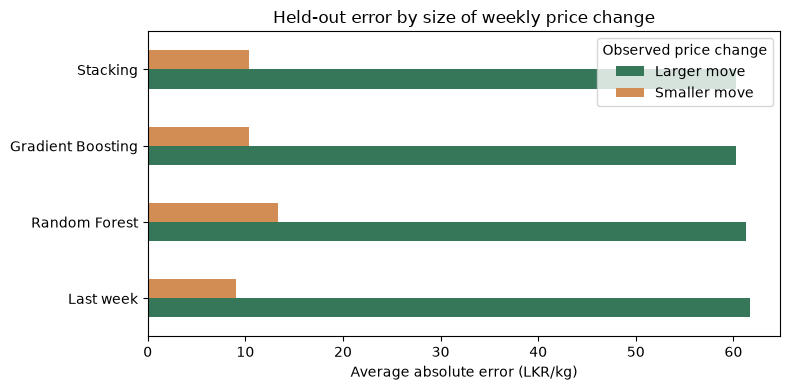

In [5]:
import matplotlib.pyplot as plt

ax = groups[methods].T.plot.barh(figsize=(8, 4), color=["#36775a", "#d18d53"])
ax.set_xlabel("Average absolute error (LKR/kg)")
ax.set_title("Held-out error by size of weekly price change")
ax.legend(title="Observed price change")
plt.tight_layout()
plt.savefig(out / "movement_errors.png", dpi=160)
plt.show()

### What the comparison shows

Repeating the last observed weekly price gave the lowest overall MAE (Rs. 27.89/kg). Among the required ensemble methods, Gradient Boosting and stacking tied at Rs. 28.26/kg. The stack selected zero forest weight on the earlier validation weeks. The base models' signed test errors had a correlation of 0.97, consistent with limited opportunity to offset each other's mistakes on this period.

For 63 crop-weeks moving more than the training median of Rs. 23/kg, boosting reduced MAE from Rs. 61.69 to Rs. 60.25. On the more frequent 113 smaller moves, its error rose from Rs. 9.05 to Rs. 10.42. The far larger error during jumps suggests that three weeks of price history provide limited warning of sharp changes. For example, Salada rose from Rs. 106/kg to Rs. 257.14/kg in the week of 11 May, while the stack forecast Rs. 110.57/kg.

These results cover eleven target weeks at one wholesale market. A weekly price here averages available observed days. Missing bulletins and exclusion of weeks with low coverage limit generalisation. The holdout simulates weekly use: after each week ends, its actual observed price becomes available for later forecasts. The magnitude of the upcoming change is unknown at forecast time.